In [1]:
import numpy as np
import matplotlib.pyplot as plt

from som_rl.som.som_backend import SharpZSOMBackend, SharpZBackendConfig
from som_rl.env.schedules import SchedulerConfig, FixedScheduler, HitGatedScheduler, PlateauGatedScheduler
from som_rl.env.env import (
    SOMEnergyEnvConfig,
    EnvTeleportNodeRandomBin,
)


In [2]:
DATA = "data"  # adjust

npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")  # (Nphot,)
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy")  # (40000,)
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy")  # (Nref,) in [0..10]

weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")  # (L,40000)

# umatrix: if you already extracted it from the pickled somoclu object, load it.
# If not, set to None for now.
umatrix = np.load(f"{DATA}/umat.npy")  # (200,200)

In [3]:
b_cfg = SharpZBackendConfig(
    grid_shape=(200,200),
    num_bins=11,
    objective_mode="energy",
    proposal_bin_mode="uniform_other"
)

som = SharpZSOMBackend(
    cfg=b_cfg,
    dd=dd, dr=dr, rd=rd, rr=rr,
    node_indices_photo=node_indices_photo,
    initial_node_bins=initial_node_bins,
    reference_labels=reference_labels,
    umatrix=umatrix,
    weighted_clusters=weighted_clusters,
)

print("E0:", som.energy_E())
print("levels:", som.levels_available() if hasattr(som, "levels_available") else (som.weighted_clusters.shape[0] if som.weighted_clusters is not None else 0))


E0: 0.023775093565945846
levels: 201


In [4]:
# Scheduler behavior checks (fixed/frozen + advance_time_on)

cfg_fixed = SchedulerConfig(
    max_steps=5,
    level_min=1,
    level_max=3,
    T_max=1.0,
    T_min=0.1,
    temp_mode="linear",
    temp_evolve_with="steps",
    level_fixed=2,
    temp_fixed=0.5,
    floor_fixed=0.01,
    advance_time_on="accept",
)

sched_fixed = FixedScheduler(cfg_fixed)

lvl0, T0, f0 = sched_fixed.current_params()
print("fixed params:", lvl0, T0, f0)
assert lvl0 == 2 and np.isclose(T0, 0.5) and np.isclose(f0, 0.01)
assert sched_fixed.step_idx == 0

# Not accepted -> no time advance
sched_fixed.update(accepted=False, dE=0.0, E=0.0, step_idx=0, is_noop=False)
assert sched_fixed.step_idx == 0

# Accepted -> time advances
sched_fixed.update(accepted=True, dE=0.0, E=0.0, step_idx=0, is_noop=False)
assert sched_fixed.step_idx == 1

# Env integration: scheduler floor should populate env.min_delta_E
s_cfg_floor = SchedulerConfig(
    max_steps=10,
    level_min=100,
    level_max=100,
    T_max=1.0,
    T_min=0.01,
    temp_mode="exp",
    floor_fixed=0.123,
)

sched_floor = FixedScheduler(s_cfg_floor)

env_cfg = SOMEnergyEnvConfig(
    grid_shape=(200, 200),
    obs_mode="patch",
    patch_size=9,
    max_steps=10,
    initial_level=100,
    initial_temperature=1.0,
)

env = EnvTeleportNodeRandomBin(som, env_cfg, scheduler=sched_floor)
obs, info = env.reset()
print("env floor:", env.min_delta_E, "level:", env.level, "T:", env.temperature)
assert np.isclose(env.min_delta_E, 0.123)


fixed params: 2 0.5 0.01
env floor: 0.123 level: 100 T: 1.0


In [5]:
# Env observation space + sample observations

obs_cfg = SOMEnergyEnvConfig(
    grid_shape=(200, 200),
    obs_mode="patch",
    patch_size=9,
    include_umatrix=True,
    include_cluster_features=True,
    include_empty_mask=True,
    include_visit_count=True,
    include_recent_mask=True,
    recent_cooldown_steps=10,
    max_steps=20,
    initial_level=50,
    initial_temperature=1.0,
)

obs_sched = FixedScheduler(
    SchedulerConfig(
        max_steps=20,
        level_min=50,
        level_max=50,
        T_max=1.0,
        T_min=0.1,
        temp_mode="exp",
        floor_fixed=1e-5,
    )
)

env_obs = EnvTeleportNodeRandomBin(som, obs_cfg, scheduler=obs_sched)
obs, info = env_obs.reset(seed=0)

print("obs space:", env_obs.observation_space)
for k, v in obs.items():
    arr = np.asarray(v)
    if arr.size > 0:
        print(f"{k:>16} shape={arr.shape} dtype={arr.dtype} min={arr.min():.4g} max={arr.max():.4g}")
    else:
        print(f"{k:>16} shape={arr.shape} dtype={arr.dtype}")

# run a few actions
for i in range(5):
    action = env_obs.action_space.sample()
    obs, reward, terminated, truncated, info = env_obs.step(action)
    print(
        f"step {i}: accepted={info['accepted']} dE={info['dE']:.4g} "
        f"level={info['level']} T={info['T']:.4g} floor={env_obs.min_delta_E:.4g} reward={reward:.4g}"
    )


obs space: Dict('bins': Box(-1, 10, (9, 9), int16), 'cluster_boundary': Box(0, 1, (9, 9), uint8), 'cluster_size': Box(0.0, 1.0, (9, 9), float32), 'cursor': Box(0, 200, (2,), int32), 'empty': Box(0, 1, (9, 9), uint8), 'recent': Box(0, 1, (9, 9), uint8), 'scalars': Box(-inf, inf, (4,), float32), 'umatrix': Box(-inf, inf, (9, 9), float32), 'visit_count': Box(0.0, 1.0, (9, 9), float32))
            bins shape=(9, 9) dtype=int16 min=1 max=2
          cursor shape=(2,) dtype=int32 min=127 max=170
           empty shape=(9, 9) dtype=uint8 min=0 max=0
         umatrix shape=(9, 9) dtype=float32 min=0.03071 max=0.03908
cluster_boundary shape=(9, 9) dtype=uint8 min=0 max=1
    cluster_size shape=(9, 9) dtype=float32 min=0.01896 max=0.08057
     visit_count shape=(9, 9) dtype=float32 min=0 max=0
          recent shape=(9, 9) dtype=uint8 min=0 max=0
         scalars shape=(4,) dtype=float32 min=0.02378 max=1
step 0: accepted=False dE=-5.444e-06 level=50 T=1 floor=1e-05 reward=-5.444e-06
step 1: ac

levels: [30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 31, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 34, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36,

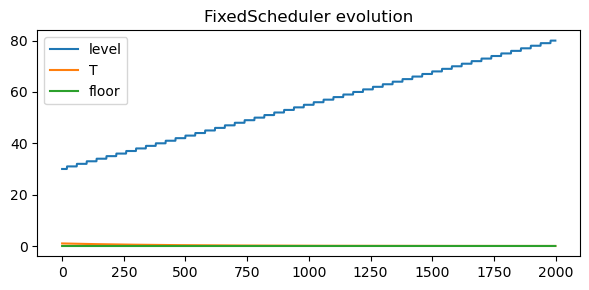

In [6]:
# Scheduler evolution checks (level/temp/floor)

# FixedScheduler: level/temperature/floor evolve with steps
sch_cfg = SchedulerConfig(
    max_steps=2000,
    level_min=30,
    level_max=80,
    T_max=1.0,
    T_min=0.01,
    temp_mode="exp",
    temp_evolve_with="steps",
    min_abs_deltaE=1e-5,
    max_abs_deltaE=1e-2,
    floor_evolve_with="temp",
    floor_power=1.0,
    advance_time_on="step",
)

sch = FixedScheduler(sch_cfg)

levels, temps, floors = [], [], []
for i in range(2000):
    lvl, T, f = sch.current_params()
    levels.append(lvl)
    temps.append(T)
    floors.append(f)
    sch.update(accepted=True, dE=0.0, E=0.0, step_idx=i, is_noop=False)

print("levels:", levels)
print("temps:", [round(t, 4) for t in temps])
print("floors:", [round(f, 6) for f in floors])

plt.figure(figsize=(6, 3))
plt.plot(levels, label="level")
plt.plot(temps, label="T")
plt.plot(floors, label="floor")
plt.legend(); plt.title("FixedScheduler evolution")
plt.tight_layout()

# HitGatedScheduler: level advances on accepted non-noop hits
hit_cfg = SchedulerConfig(
    max_steps=100,
    level_min=1,
    level_max=3,
    min_accepts_per_level=2,
    T_max=1.0,
    T_min=0.5,
    temp_mode="linear",
)

hit = HitGatedScheduler(hit_cfg)

hit_levels = []
for i in range(6):
    lvl, T, f = hit.current_params()
    hit_levels.append(lvl)
    accepted = (i % 2 == 1)  # accept every other step
    hit.update(accepted=accepted, dE=0.1 if accepted else -0.1, E=0.0, step_idx=i, is_noop=False)

print("hit-gated levels:", hit_levels)


Initial scalars: [0.25       1.         0.02377509 1.        ] cursor: [170 127]
After 2000 steps scalars: [0.4        0.01       0.02764871 0.        ] cursor: [54 88]


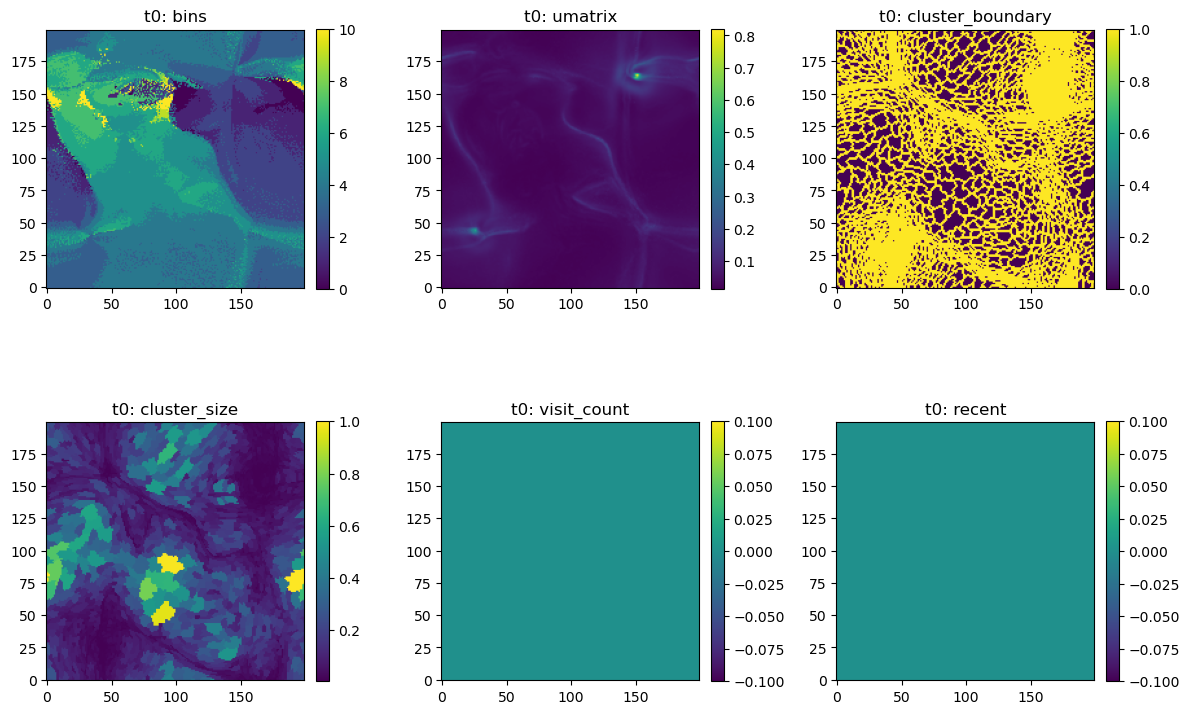

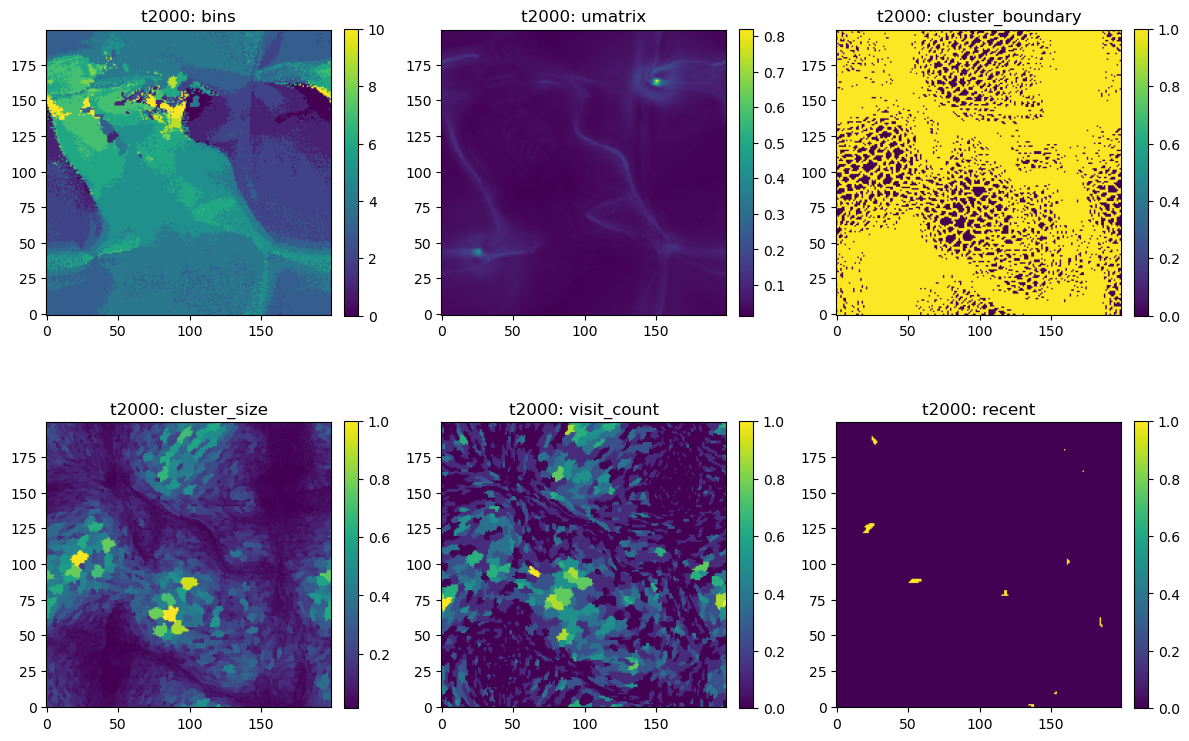

In [7]:
# Global obs visualization helper

def _plot_global_obs(obs, title_prefix=""):
    # Non-scalar channels (skip cursor/scalars)
    keys = [
        k for k in obs.keys()
        if k not in {"scalars", "cursor"}
    ]
    n = len(keys)
    if n == 0:
        print("No non-scalar channels to plot.")
        return

    ncols = 3
    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(4 * ncols, 4 * nrows))

    for i, k in enumerate(keys, start=1):
        plt.subplot(nrows, ncols, i)
        arr = np.asarray(obs[k])
        if arr.ndim != 2:
            # fallback for unexpected shapes
            arr = arr.squeeze()
        plt.imshow(arr, origin="lower")
        plt.colorbar(fraction=0.046, pad=0.04)
        plt.title(f"{title_prefix}{k}")

    plt.tight_layout()


def inspect_global_obs(
    *,
    som_backend,
    env_cfg: SOMEnergyEnvConfig,
    scheduler,
    n_steps: int = 5,
    seed: int = 0,
):
    """
    Build a GLOBAL obs env, print scalar obs, and plot non-scalar channels
    before and after n_steps actions.
    """
    # Force global view for full diagnostics
    env_cfg = SOMEnergyEnvConfig(
        **{**env_cfg.__dict__, "obs_mode": "global"}
    )

    env = EnvTeleportNodeRandomBin(som_backend, env_cfg, scheduler=scheduler)
    obs0, info0 = env.reset(seed=seed)

    print("Initial scalars:", obs0["scalars"], "cursor:", obs0["cursor"])
    _plot_global_obs(obs0, title_prefix="t0: ")

    for i in range(int(n_steps)):
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)
        if terminated or truncated:
            break

    print(f"After {i+1} steps scalars:", obs["scalars"], "cursor:", obs["cursor"])
    _plot_global_obs(obs, title_prefix=f"t{i+1}: ")

    return obs0, obs


# Example usage
full_cfg = SOMEnergyEnvConfig(
    grid_shape=(200, 200),
    obs_mode="global",  # will be forced anyway
    patch_size=9,
    include_umatrix=True,
    include_cluster_features=True,
    include_empty_mask=False,
    include_visit_count=True,
    include_recent_mask=True,
    recent_cooldown_steps=10,
    max_steps=2000,
    initial_level=50,
    initial_temperature=1.0,
)

full_sched = FixedScheduler(
    SchedulerConfig(
        max_steps=2000,
        level_min=50,
        level_max=80,
        T_max=1.0,
        T_min=0.01,
        temp_mode="exp",
        floor_fixed=1e-5,
    )
)

_ = inspect_global_obs(
    som_backend=som,
    env_cfg=full_cfg,
    scheduler=full_sched,
    n_steps=2000,
    seed=0,
)


In [8]:
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych
perfect = get_perfect_bins()

node=0 current_bin=3 level=50
perfect_bin=3
top bins: [(3, 0.0), (2, -3.6149844068803644e-05), (4, -3.623297278501983e-05), (5, -5.347599518396029e-05), (1, -5.5244099851716605e-05)]
node=12345 current_bin=4 level=50
perfect_bin=5
top bins: [(5, -4.036363585601527e-06), (4, -7.490596305125691e-06), (3, -1.2939142120131641e-05), (2, -1.4246829271216677e-05), (6, -1.6825436275284822e-05)]


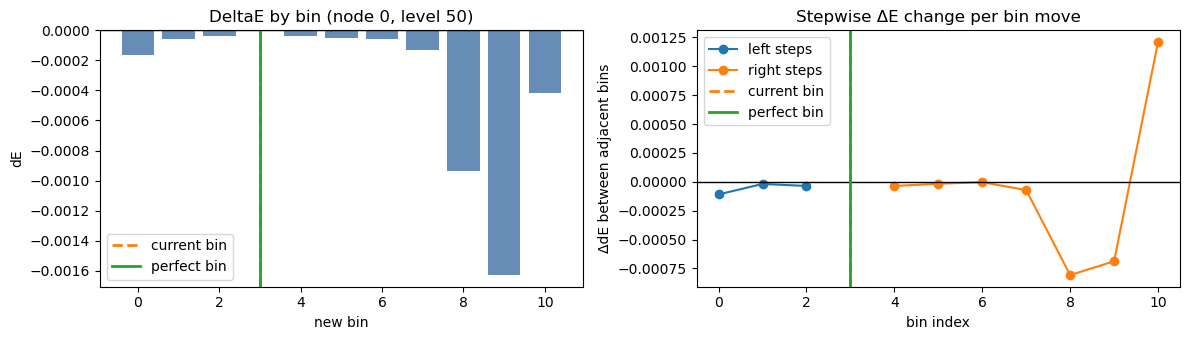

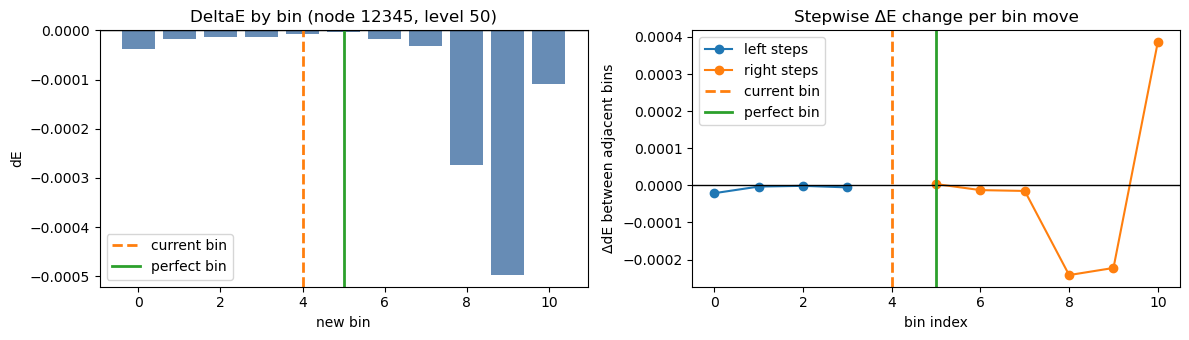

In [9]:
# Delta-E per bin change (greedy check + perfect bin comparison)

def deltaE_by_bin(som_backend, node_id: int, level: int | None = None):
    """Return dict: bin -> dE for setting this node/cluster to that bin."""
    cur_bin = int(som_backend.current_bins[int(node_id)])
    dE_map = {}

    for b in range(int(som_backend.K)):
        try:
            proposal = som_backend.make_proposal_set_bin(new_bin=b, node=node_id, level=level)
        except Exception:
            dE_map[b] = np.nan
            continue

        evald = som_backend.evaluate_proposal_deltaE(proposal)
        dE_map[b] = float(evald["dE"])
        som_backend.revert(evald["undo"])  # restore state

    return cur_bin, dE_map


def _adjacent_dE_steps(dE_map, cur_bin: int):
    """Return stepwise dE differences moving away from cur_bin (left/right)."""
    K = len(dE_map)
    left_x, left_d = [], []
    right_x, right_d = [], []

    # left: cur-1, cur-2, ...
    for b in range(cur_bin - 1, -1, -1):
        prev = b + 1
        left_x.append(b)
        left_d.append(dE_map[b] - dE_map[prev])

    # right: cur+1, cur+2, ...
    for b in range(cur_bin + 1, K):
        prev = b - 1
        right_x.append(b)
        right_d.append(dE_map[b] - dE_map[prev])

    return (left_x, left_d, right_x, right_d)


def show_deltaE_for_node(
    node_id: int,
    level: int | None = None,
    perfect_bins: np.ndarray | None = perfect,
):
    cur_bin, dE_map = deltaE_by_bin(som, node_id=node_id, level=level)
    perfect_bin = int(perfect_bins[node_id]) if perfect_bins is not None else None

    print(f"node={node_id} current_bin={cur_bin} level={level}")
    if perfect_bin is not None:
        print(f"perfect_bin={perfect_bin}")

    # Sort by best dE
    items = sorted(dE_map.items(), key=lambda kv: kv[1], reverse=True)
    print("top bins:", items[:5])

    xs = list(dE_map.keys())
    ys = [dE_map[k] for k in xs]

    # Plot: dE by bin + stepwise deltas away from current bin
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

    ax = axes[0]
    ax.bar(xs, ys, color="#4C78A8", alpha=0.85)
    ax.axhline(0.0, color="k", linewidth=1)
    ax.axvline(cur_bin, color="#FF7F0E", linestyle="--", linewidth=2, label="current bin")
    if perfect_bin is not None:
        ax.axvline(perfect_bin, color="#2CA02C", linestyle="-", linewidth=2, label="perfect bin")
    ax.set_title(f"DeltaE by bin (node {node_id}, level {level})")
    ax.set_xlabel("new bin")
    ax.set_ylabel("dE")
    ax.legend()

    # Stepwise differences from current bin
    ax2 = axes[1]
    left_x, left_d, right_x, right_d = _adjacent_dE_steps(dE_map, cur_bin)
    ax2.plot(left_x, left_d, "o-", label="left steps")
    ax2.plot(right_x, right_d, "o-", label="right steps")
    ax2.axhline(0.0, color="k", linewidth=1)
    ax2.axvline(cur_bin, color="#FF7F0E", linestyle="--", linewidth=2, label="current bin")
    if perfect_bin is not None:
        ax2.axvline(perfect_bin, color="#2CA02C", linestyle="-", linewidth=2, label="perfect bin")
    ax2.set_title("Stepwise ΔE change per bin move")
    ax2.set_xlabel("bin index")
    ax2.set_ylabel("ΔdE between adjacent bins")
    ax2.legend()

    plt.tight_layout()


# Example checks
# If you have a perfect-bin array (e.g. perfect_node_bins), pass it in.
# show_deltaE_for_node(node_id=0, level=50, perfect_bins=perfect_node_bins)
show_deltaE_for_node(node_id=0, level=50)
show_deltaE_for_node(node_id=12345, level=50)


positive nodes found: 65
top hits (node, cur_bin, best_bin, best_dE):
[(28682, 7, 10, 0.0003628177366338421), (24098, 5, 8, 0.00016217400899002157), (27670, 9, 8, 0.00016036976474909093), (27870, 6, 8, 0.00016036976474909093), (32638, 5, 8, 0.00014723782396868987), (32636, 4, 8, 0.00014723782396868987), (31804, 6, 8, 0.00013561558596462964), (29283, 10, 10, 0.00012341617025949173), (32031, 5, 8, 5.9914836540487376e-05), (28458, 7, 6, 3.455566312468225e-05)]
node=28682 current_bin=7 level=50
perfect_bin=10
top bins: [(10, 0.0003628177366338421), (4, 0.0002783375541750427), (3, 0.00027441899144450485), (2, 0.0002705553162951693), (1, 0.00026592904115891464)]


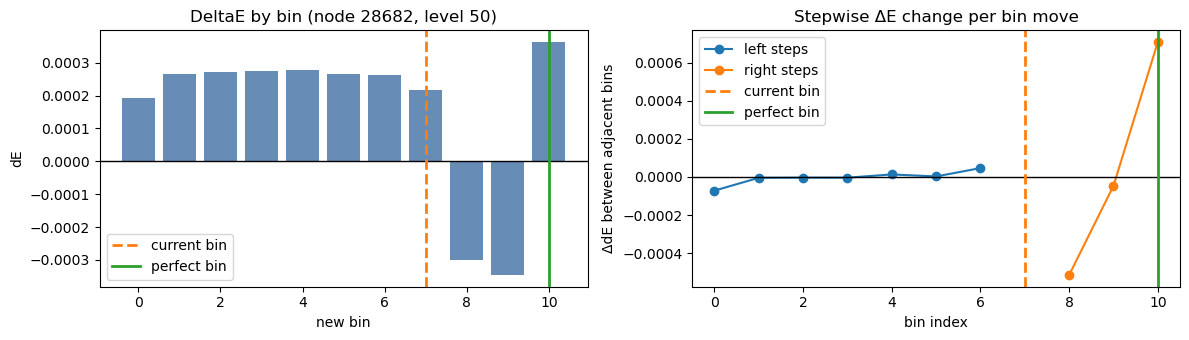

In [10]:
# Find nodes with any positive dE for some bin

def find_positive_nodes(n_samples=200, level=50, seed=0):
    rng = np.random.default_rng(seed)
    N = int(som.N)
    candidates = rng.integers(0, N, size=int(n_samples))

    hits = []
    for node_id in candidates:
        cur_bin, dE_map = deltaE_by_bin(som, node_id=int(node_id), level=level)
        # best positive change
        best_bin, best_dE = max(dE_map.items(), key=lambda kv: kv[1])
        if best_dE > 0:
            hits.append((int(node_id), int(cur_bin), int(best_bin), float(best_dE)))

    hits.sort(key=lambda x: x[3], reverse=True)
    return hits


hits = find_positive_nodes(n_samples=200, level=50, seed=12)
print(f"positive nodes found: {len(hits)}")
print("top hits (node, cur_bin, best_bin, best_dE):")
print(hits[:10])

# Optional: visualize one of them
if hits:
    node_id, cur_bin, best_bin, best_dE = hits[0]
    show_deltaE_for_node(node_id=node_id, level=50)


positive nodes found: 66
top hits (node, cur_bin, best_bin, best_dE):
[(28682, 7, 10, 0.0001815793355683347), (27870, 6, 8, 6.920788655792945e-05), (32638, 5, 8, 3.559235470215055e-05), (31804, 6, 8, 3.2700797690094624e-05), (28458, 7, 6, 2.7996123135750478e-05), (24098, 5, 8, 2.7951119906464983e-05), (27470, 9, 9, 2.297917012394901e-05), (27670, 9, 8, 1.694291663418418e-05), (31215, 7, 8, 1.4958282163267389e-05), (32031, 5, 8, 1.4685152423889875e-05)]
node=28682 current_bin=7 level=50
perfect_bin=10
top bins: [(10, 0.0003628177366338421), (4, 0.0002783375541750427), (3, 0.00027441899144450485), (2, 0.0002705553162951693), (1, 0.00026592904115891464)]


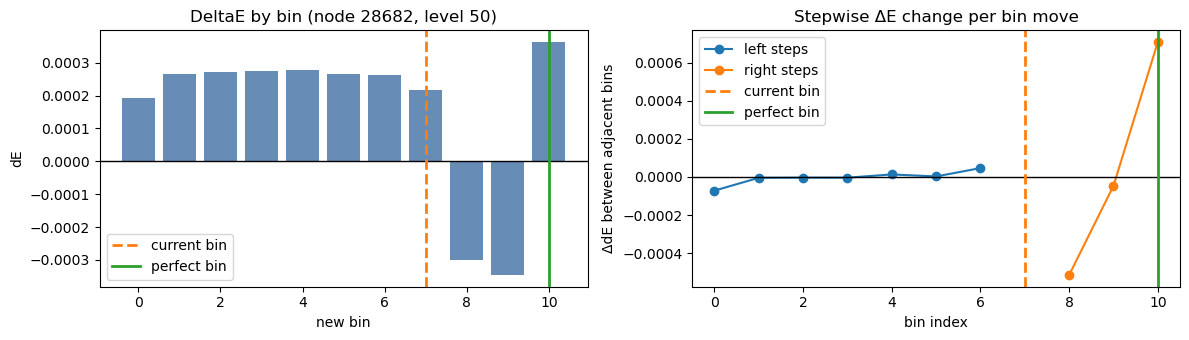

In [11]:
hits = find_positive_nodes(n_samples=200, level=80, seed=12)
print(f"positive nodes found: {len(hits)}")
print("top hits (node, cur_bin, best_bin, best_dE):")
print(hits[:10])

if hits:
    node_id, cur_bin, best_bin, best_dE = hits[0]
    show_deltaE_for_node(node_id=node_id, level=50)

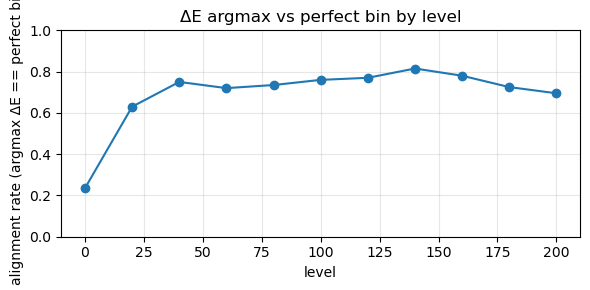

In [12]:
# Alignment analysis: max ΔE bin vs perfect bin across levels

def alignment_vs_level(
    *,
    som_backend,
    perfect_bins: np.ndarray,
    levels: list[int],
    n_samples: int = 200,
    seed: int = 0,
    only_gal_nodes: bool = True,
):
    rng = np.random.default_rng(seed)
    N = int(som_backend.N)

    if only_gal_nodes:
        eligible = np.flatnonzero(som_backend.node_gal_counts > 0)
    else:
        eligible = np.arange(N)

    results = []
    for lvl in levels:
        # sample nodes
        if n_samples is None or n_samples >= len(eligible):
            nodes = eligible
        else:
            nodes = rng.choice(eligible, size=int(n_samples), replace=False)

        hits = 0
        total = 0
        for node_id in nodes:
            cur_bin, dE_map = deltaE_by_bin(som_backend, node_id=int(node_id), level=int(lvl))
            # argmax dE
            best_bin = max(dE_map.items(), key=lambda kv: kv[1])[0]
            if int(best_bin) == int(perfect_bins[int(node_id)]):
                hits += 1
            total += 1

        acc = hits / max(total, 1)
        results.append((int(lvl), acc, total))

    return results


# Example usage
perfect_node_bins = perfect  # should be your injected perfect-bin array
levels = list(range(0, som.levels_available(), 20))  # coarse grid
results = alignment_vs_level(som_backend=som, perfect_bins=perfect_node_bins, levels=levels, n_samples=200)

# Plot
lvls = [r[0] for r in results]
accs = [r[1] for r in results]
plt.figure(figsize=(6, 3))
plt.plot(lvls, accs, marker="o")
plt.xlabel("level")
plt.ylabel("alignment rate (argmax ΔE == perfect bin)")
plt.title("ΔE argmax vs perfect bin by level")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()


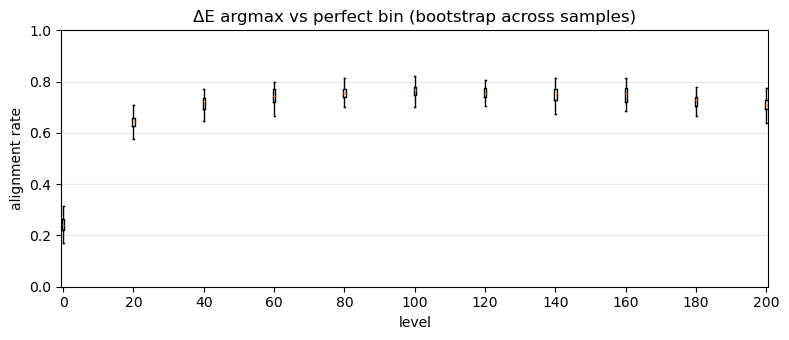

In [13]:
# Box plot for alignment (bootstrap over random node samples)

def alignment_vs_level_bootstrap(
    *,
    som_backend,
    perfect_bins: np.ndarray,
    levels: list[int],
    n_samples: int = 200,
    n_trials: int = 50,
    seed: int = 0,
    only_gal_nodes: bool = True,
):
    """Return dict[level] -> list[alignment rates] across trials."""
    rng = np.random.default_rng(seed)
    N = int(som_backend.N)

    if only_gal_nodes:
        eligible = np.flatnonzero(som_backend.node_gal_counts > 0)
    else:
        eligible = np.arange(N)

    out = {int(lvl): [] for lvl in levels}

    for _ in range(int(n_trials)):
        for lvl in levels:
            if n_samples is None or n_samples >= len(eligible):
                nodes = eligible
            else:
                nodes = rng.choice(eligible, size=int(n_samples), replace=False)

            hits = 0
            total = 0
            for node_id in nodes:
                cur_bin, dE_map = deltaE_by_bin(som_backend, node_id=int(node_id), level=int(lvl))
                best_bin = max(dE_map.items(), key=lambda kv: kv[1])[0]
                if int(best_bin) == int(perfect_bins[int(node_id)]):
                    hits += 1
                total += 1

            acc = hits / max(total, 1)
            out[int(lvl)].append(acc)

    return out


# Example usage (reuse levels + perfect_node_bins from alignment cell)
boot = alignment_vs_level_bootstrap(
    som_backend=som,
    perfect_bins=perfect_node_bins,
    levels=levels,
    n_samples=200,
    n_trials=50,
    seed=0,
)

plt.figure(figsize=(8, 3.5))
plt.boxplot([boot[lvl] for lvl in levels], positions=levels, widths=0.6, showfliers=False)
plt.xlabel("level")
plt.ylabel("alignment rate")
plt.title("ΔE argmax vs perfect bin (bootstrap across samples)")
plt.ylim(0, 1)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
